# Homework 6 — Smart Beta & Momentum

**FINM 36700 — Portfolio and Risk Management**

This notebook covers two case studies:

* **Part A — Smart Beta and Factor Investing** (HBS case *Smart Beta Exchange-Traded-Funds and Factor Investing*), data: `factor_pricing_data.xlsx`
* **Part B — AQR Momentum Strategies** (HBS case on AQR's momentum funds), data: `momentum_data.xlsx`

READING sections are ungraded and left out. All statistics are **annualized** from monthly data: mean × 12, vol × √12, Sharpe = mean/vol.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)


def summary_stats(df, ann=12):
    # Annualized mean, vol, and Sharpe of excess-return columns
    df = pd.DataFrame(df)
    out = pd.DataFrame({"Mean": df.mean() * ann, "Vol": df.std() * np.sqrt(ann)})
    out["Sharpe"] = out["Mean"] / out["Vol"]
    return out


def tangency_weights(df):
    # Tangency weights w ∝ Σ^-1 μ, normalized to sum to one
    w = np.linalg.solve(df.cov(), df.mean())
    return pd.Series(w / w.sum(), index=df.columns, name="Tangency weight")

---
# Part A — Smart Beta and Factor Investing

## 2. The Factors

In [2]:
FILE_SB = "factor_pricing_data.xlsx"
factors = pd.read_excel(FILE_SB, sheet_name="factors (excess returns)", index_col="Date")
ports = pd.read_excel(FILE_SB, sheet_name="portfolios (excess returns)", index_col="Date")
ports.columns = ports.columns.str.strip()

print(f"Factors:    {factors.index[0]:%Y-%m} to {factors.index[-1]:%Y-%m}, {len(factors)} months, {factors.columns.tolist()}")
print(f"Portfolios: {ports.shape[1]} industry portfolios (excess returns)")

Factors:    1980-01 to 2025-04, 544 months, ['MKT', 'SMB', 'HML', 'RMW', 'CMA', 'UMD']
Portfolios: 49 industry portfolios (excess returns)


### 2.1 Univariate statistics of the six factors

In [3]:
fac_stats = summary_stats(factors)
fac_stats

,Mean,Vol,Sharpe
MKT,0.0849,0.1564,0.5432
SMB,0.0054,0.1014,0.0535
HML,0.0265,0.1089,0.2434
RMW,0.0451,0.0831,0.5435
CMA,0.0277,0.0725,0.3819
UMD,0.0618,0.1535,0.4023


### 2.2 Risk premia, full sample vs. 2015–present

In [4]:
comp = pd.concat(
    {"Full sample": summary_stats(factors), "2015-present": summary_stats(factors.loc["2015":])},
    axis=1,
)
comp

Full sample               2015-present               
           Mean    Vol Sharpe         Mean    Vol  Sharpe
MKT      0.0849 0.1564 0.5432       0.1074 0.1586  0.6775
SMB      0.0054 0.1014 0.0535      -0.0278 0.1035 -0.2686
HML      0.0265 0.1089 0.2434      -0.0156 0.1308 -0.1193
RMW      0.0451 0.0831 0.5435       0.0447 0.0729  0.6127
CMA      0.0277 0.0725 0.3819      -0.0130 0.0823 -0.1578
UMD      0.0618 0.1535 0.4023       0.0252 0.1384  0.1822

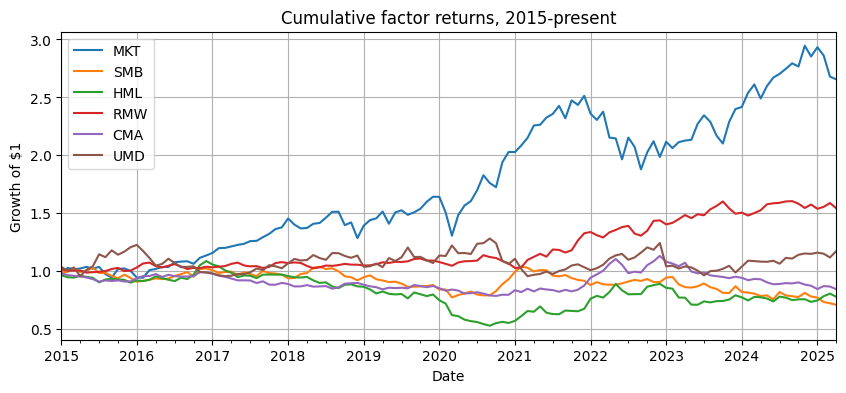

In [5]:
(1 + factors.loc["2015":]).cumprod().plot(figsize=(10, 4), title="Cumulative factor returns, 2015-present", grid=True)
plt.ylabel("Growth of $1")
plt.show()

**Does each factor have a positive risk premium?**
Over the full sample (1980–2025), yes: all six factors have a positive average excess return. The sizes differ a lot, though:

* **MKT** (8.5%/yr, Sharpe 0.54), **RMW** (4.5%, Sharpe 0.54), **UMD** (6.2%, Sharpe 0.40) and **CMA** (2.8%, Sharpe 0.38) earn sizable premia.
* **HML** is modest (2.7%, Sharpe 0.24).
* **SMB** is barely positive (0.5%, Sharpe 0.05). Its premium is economically close to zero.

**Since the case (2015–present):** performance has been poor for most of the "style" factors.

* **SMB, HML and CMA all have *negative* average returns.** Small, value and conservative-investment stocks have underperformed.
* **UMD** stayed positive but much weaker (2.5%, Sharpe 0.18).
* **RMW** (profitability) held up well (Sharpe ≈ 0.61).
* **MKT** did better than its long-run average (Sharpe ≈ 0.68).

For smart-beta products sold around 2015 on value and size tilts, the realized results were disappointing.

### 2.3 Correlation matrix

In [6]:
corr = factors.corr()
corr.round(2)

,MKT,SMB,HML,RMW,CMA,UMD
MKT,1.0000,0.2300,-0.2100,-0.2500,-0.3500,-0.1800
SMB,0.2300,1.0000,-0.0300,-0.4100,-0.0500,-0.0600
HML,-0.2100,-0.0300,1.0000,0.2200,0.6800,-0.2100
RMW,-0.2500,-0.4100,0.2200,1.0000,0.1400,0.0700
CMA,-0.3500,-0.0500,0.6800,0.1400,1.0000,0.0000
UMD,-0.1800,-0.0600,-0.2100,0.0700,0.0000,1.0000


In [7]:
# Largest pairwise correlations (in absolute value)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).to_frame("corr")

corr
HML CMA  0.6808
SMB RMW -0.4127
MKT CMA -0.3519
    RMW -0.2498
    SMB  0.2281

**Does the construction keep correlations small?** Mostly yes. Each factor is built from independent 2×3 sorts (size × characteristic), and its long and short legs are averaged across small and big stocks, which neutralizes size. As a result most pairwise correlations are below 0.25 in absolute value. The exceptions:

* **HML–CMA ≈ 0.68.** This is by far the largest correlation: value firms tend to be low-investment (conservative) firms.
* **SMB–RMW ≈ −0.41.** Small firms tend to be less profitable.
* **MKT–CMA ≈ −0.35.**

**Is HML redundant?** It looks that way. HML is highly correlated with CMA and also positively correlated with RMW (0.22). Most of its variation, and its premium, can be spanned by the other factors, as Fama and French argue for the 5-factor model. The tangency weights below confirm this.

### 2.4 Tangency weights

In [8]:
tan6 = tangency_weights(factors)
tan4 = tangency_weights(factors[["MKT", "SMB", "HML", "UMD"]])
tan_tbl = pd.concat({"6 factors": tan6, "MKT, SMB, HML, UMD": tan4}, axis=1)
tan_tbl

,6 factors,"MKT, SMB, HML, UMD"
MKT,0.2161,0.3715
SMB,0.0667,-0.0537
HML,-0.0197,0.3679
RMW,0.3059,NaN
CMA,0.3166,NaN
UMD,0.1144,0.3143


In [9]:
def port_sharpe(df, w):
    r = df[w.index] @ w
    return r.mean() / r.std() * np.sqrt(12)


pd.Series({"6 factors": port_sharpe(factors, tan6),
           "MKT, SMB, HML, UMD": port_sharpe(factors, tan4)}, name="Tangency Sharpe (ann.)").to_frame()

,Tangency Sharpe (ann.)
6 factors,1.1944
"MKT, SMB, HML, UMD",0.9063


**Six-factor tangency**

* **Most important:** CMA (≈ 32%), RMW (≈ 31%) and MKT (≈ 22%), followed by UMD (≈ 11%).
* **Least important:** HML gets a slightly *negative* weight (≈ −2%), and SMB gets only ≈ 7%.
* The 6-factor tangency Sharpe ratio is ≈ 1.19, versus ≈ 0.91 for the 4-factor set.

**Are low-mean factors still useful?** Yes. CMA has a low mean (2.8%) but receives the largest weight, because it has low volatility and is negatively correlated with MKT (−0.35). That makes it a strong hedge and diversifier. Tangency weights depend on each factor's *marginal* contribution given the others, not on its standalone mean. The opposite holds too: HML has a positive mean but gets no weight, because CMA and RMW already span it.

**Four-factor tangency (MKT, SMB, HML, UMD):** Once CMA and RMW are removed, **HML becomes important** (≈ 37%, about equal to MKT), and UMD stays large (≈ 31%). **SMB turns slightly negative** (≈ −5%).

**Conclusion:**

* The importance of a style depends on which other styles are available. HML matters only as a stand-in for CMA/RMW.
* **Size (SMB) adds essentially nothing** in either specification.
* **Momentum is consistently valuable**, because of its negative correlation with value and the market.
* **Profitability and investment are the most valuable additions** to the market.

---
## 3. Testing Modern Linear Pricing Models

Four models:
* **CAPM:** MKT
* **FF3:** MKT, SMB, HML
* **FF5:** MKT, SMB, HML, RMW, CMA
* **AQR:** MKT, HML, RMW, UMD

For each of the 49 industry portfolios, estimate the time-series regression
$\tilde r^i_t = \alpha^i + \boldsymbol\beta^{i\prime}\tilde{\mathbf f}_t + \varepsilon^i_t$.
Alphas are annualized (× 12).

In [10]:
MODELS = {
    "CAPM": ["MKT"],
    "FF3": ["MKT", "SMB", "HML"],
    "FF5": ["MKT", "SMB", "HML", "RMW", "CMA"],
    "AQR": ["MKT", "HML", "RMW", "UMD"],
}


def ts_test(assets, facs):
    # Time-series regressions of each asset on the factors. Returns alpha (annualized), betas, R^2.
    X = sm.add_constant(facs)
    rows = {}
    for col in assets:
        res = sm.OLS(assets[col], X, missing="drop").fit()
        rows[col] = {"alpha": res.params["const"] * 12, **res.params.drop("const").to_dict(), "R2": res.rsquared}
    return pd.DataFrame(rows).T


ts_results = {m: ts_test(ports, factors[f]) for m, f in MODELS.items()}

### 3.1 AQR 4-factor model: alpha and R² for each industry

In [11]:
aqr = ts_results["AQR"]
aqr[["alpha", "R2"]]

,alpha,R2
Agric,0.0110,0.3404
Food,0.0042,0.4607
Soda,0.0182,0.3044
Beer,0.0111,0.4207
Smoke,0.0430,0.2657
Toys,-0.0346,0.5092
Fun,0.0413,0.6095
Books,-0.0354,0.6899
Hshld,-0.0102,0.5586
Clths,-0.0229,0.6181


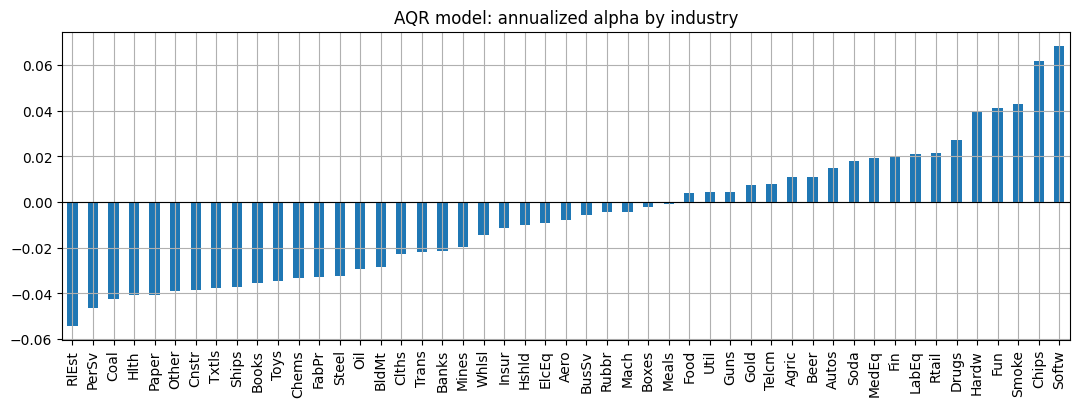

In [12]:
ax = aqr["alpha"].sort_values().plot.bar(figsize=(13, 4), title="AQR model: annualized alpha by industry", grid=True)
ax.axhline(0, color="k", lw=0.8)
plt.show()

### 3.2 MAE of the AQR alphas

In [13]:
mae_aqr = aqr["alpha"].abs().mean()
print(f"AQR model MAE of alphas (annualized): {mae_aqr:.4f}  ({mae_aqr:.2%} per year)")

AQR model MAE of alphas (annualized): 0.0246  (2.46% per year)


**Should alphas be large or small?** If the model priced assets correctly, every alpha would be zero (up to sampling error). Expected excess returns would then be fully explained by factor betas times factor premia, $\mathbb E[\tilde r^i] = \boldsymbol\beta^{i\prime}\mathbb E[\tilde{\mathbf f}]$.

**Does the MAE support the model?** Only partly. An MAE of about **2.5% per year** is economically large: it is roughly a third of the market premium (8.5%). A few industries have alphas beyond ±5% (Software ≈ +6.9%, Chips ≈ +6.2%, Real Estate ≈ −5.4%), and many more are in the 2–4% range. The model leaves substantial mispricing across industries, so the evidence for it is weak at best.

### 3.3 Compare MAE across CAPM, FF3, FF5, AQR

In [14]:
model_tbl = pd.DataFrame({
    "MAE (TS alpha)": {m: r["alpha"].abs().mean() for m, r in ts_results.items()},
    "Avg R2 (TS)": {m: r["R2"].mean() for m, r in ts_results.items()},
})
model_tbl

,MAE (TS alpha),Avg R2 (TS)
CAPM,0.0214,0.5244
FF3,0.0245,0.5696
FF5,0.0315,0.5939
AQR,0.0246,0.5735


**Which model fits best?** Judged by the MAE of time-series alphas on these 49 industries, the **CAPM has the smallest MAE (≈ 2.1%)**. It is followed by FF3 (≈ 2.4%) and AQR (≈ 2.5%), with **FF5 the worst (≈ 3.1%)**.

* Adding factors does not reduce industry alphas here. Industry portfolios are not sorted on size, value, profitability or investment, so they are not the test assets these factors were designed to explain.
* Adding factors changes the betas. When an industry loads on a factor whose in-sample premium does not line up with that industry's average return, the alpha grows. HML and RMW do this here (see 3.4).
* Among the multifactor models, **AQR beats FF5** and is roughly tied with FF3. Replacing SMB and CMA with UMD helps.

### 3.4 Which factors matter for pricing? Should FF include momentum?

In [15]:
# (i) Average |beta| x factor premium: how much expected return each factor "explains" on average (annualized)
prem = factors.mean() * 12
contrib = {m: (ts_results[m][f].abs() * prem[f]).mean() for m, f in MODELS.items()}
pd.DataFrame(contrib).T

,CMA,HML,MKT,RMW,SMB,UMD
CAPM,NaN,NaN,0.0862,NaN,NaN,NaN
FF3,NaN,0.0079,0.0863,NaN,0.0014,NaN
FF5,0.0069,0.0068,0.0887,0.0159,0.0017,NaN
AQR,NaN,0.0070,0.0888,0.0124,NaN,0.0062


In [16]:
# (ii) Marginal effect of each factor on the alpha MAE: add one factor at a time to CAPM and to FF3
def mae_of(fs):
    return ts_test(ports, factors[fs])["alpha"].abs().mean()

base = {"CAPM": ["MKT"], "FF3": ["MKT", "SMB", "HML"]}
add_one = {}
for b, fs in base.items():
    row = {"(base)": mae_of(fs)}
    for f in factors.columns.difference(fs):
        row[f"+ {f}"] = mae_of(fs + [f])
    add_one[b] = row
pd.DataFrame(add_one).T

,(base),+ CMA,+ HML,+ RMW,+ SMB,+ UMD
CAPM,0.0214,0.0258,0.0258,0.0228,0.0203,0.0208
FF3,0.0245,0.0234,NaN,0.0313,NaN,0.0224


Table (i) shows the average of |β| × (factor premium), i.e. how much each factor moves the model-implied expected return.

* **MKT does almost all the work** in every model. The betas on SMB and HML are modest, and SMB's premium is near zero, so SMB contributes little to pricing.
* **HML and RMW hurt the fit** (Table ii).
  * Adding HML to the CAPM raises the MAE from 2.1% to 2.6%.
  * Adding RMW to FF3 raises it from 2.4% to 3.1%.
  * This is why FF5 does worst: the betas industries have on value and profitability imply expected-return differences that their realized averages do not show.
* **UMD, CMA and SMB help, slightly.**
  * UMD lowers the MAE whether it is added to the CAPM or to FF3.
  * CMA lowers it modestly when added to FF3.
  * Their contributions to fit are small, though. No factor beyond MKT produces a large improvement for industry portfolios.

**Should Fama and French use momentum?** On this evidence, yes. Momentum is the factor that most consistently *improves* the fit: adding UMD lowers the MAE whether it is added to the CAPM or to FF3. The factor-level results point the same way: momentum has a large premium and strong diversification value (a high tangency weight in §2.4).

The usual objection is that momentum is a "non-fundamental" factor with high turnover, so its costs are higher. That is a fair concern for implementation, but it is not a reason to leave it out of a pricing model.

### 3.5 Average time-series R²

In [17]:
model_tbl[["Avg R2 (TS)"]]

,Avg R2 (TS)
CAPM,0.5244
FF3,0.5696
FF5,0.5939
AQR,0.5735


Average R² ranges from about **0.52 (CAPM) to 0.59 (FF5)**. Adding factors adds only a few percentage points; the market factor explains most of the variation. Industry portfolios carry a lot of idiosyncratic, industry-specific risk, so roughly 40–48% of their variance is left unexplained.

These factors are **not especially good for a Linear Factor Decomposition** of industry returns. A good LFD (e.g. for hedging or replication) would need R² well above this, and industry-specific factors would do better. Pricing (small alphas) and LFD (high R²) are different objectives.

### 3.6 Cross-sectional regressions (with intercept)

Using the time-series betas, run the cross-sectional regression across the 49 industries:
$\mathbb E[\tilde r^i] = \eta + \boldsymbol\beta^{i\prime}\boldsymbol\lambda + \upsilon^i$

In [18]:
mean_ret = ports.mean() * 12
cs_prem, cs_mae, cs_r2 = {}, {}, {}
for m, f in MODELS.items():
    betas = ts_results[m][f].astype(float)
    res = sm.OLS(mean_ret, sm.add_constant(betas)).fit()
    cs_prem[m] = res.params.rename({"const": "Intercept"})
    cs_mae[m] = res.resid.abs().mean()
    cs_r2[m] = res.rsquared

prem_tbl = pd.DataFrame(cs_prem).T
prem_tbl.loc["TS premia (sample mean)"] = factors.mean() * 12
prem_tbl[["Intercept"] + factors.columns.tolist()]

,Intercept,MKT,SMB,HML,RMW,CMA,UMD
CAPM,0.0869,0.0021,NaN,NaN,NaN,NaN,NaN
FF3,0.0624,0.0376,-0.0447,-0.0199,NaN,NaN,NaN
FF5,0.0600,0.0384,-0.0470,-0.0258,0.0231,-0.0243,NaN
AQR,0.0758,0.0144,NaN,-0.0326,0.0213,NaN,0.0019
TS premia (sample mean),NaN,0.0849,0.0054,0.0265,0.0451,0.0277,0.0618


In [19]:
model_tbl["MAE (CS residual)"] = pd.Series(cs_mae)
model_tbl["CS R2"] = pd.Series(cs_r2)
model_tbl

,MAE (TS alpha),Avg R2 (TS),MAE (CS residual),CS R2
CAPM,0.0214,0.5244,0.0155,0.0006
FF3,0.0245,0.5696,0.0120,0.3788
FF5,0.0315,0.5939,0.0119,0.4163
AQR,0.0246,0.5735,0.0138,0.2103


**Time-series vs. cross-sectional premia: they differ substantially.**

* **The intercepts are large.** They range from about 6% to 8.7% per year; theory says the intercept should be 0.
* **The cross-sectional market premium is far below its sample mean of 8.5%.** In the CAPM it is ≈ 0.2%, and in the multifactor models ≈ 1.4–3.8%. Industries with high market beta do not earn higher average returns; the security market line is flat.
* **Several premia flip sign.** SMB, HML and CMA come out *negative* cross-sectionally, although their sample means are positive. UMD's cross-sectional premium is near zero, versus 6.2% in the time series.

**MAE comparison:** Cross-sectional residual MAEs (≈ 1.2–1.6%) are *smaller* than the time-series alpha MAEs (≈ 2.1–3.1%). This is mechanical: the cross-sectional regression picks the premia and an intercept to minimize pricing errors, while the time-series test forces the premia to equal the factor sample means and the intercept to be zero.

The CAPM's cross-sectional R² is essentially 0: market beta explains none of the variation in average industry returns. Even with the free intercept, the large intercepts and implausible premia indicate that **none of these models prices the industry portfolios well**.

This matches the Homework 4 finding mentioned in the prompt: the cross-sectional market premium with an intercept is far from (here, much smaller than) the sample mean market excess return.

---
# Part B — AQR Momentum Strategies

## 2. Investigating Momentum

The FF momentum factor is
$\tilde r^{\text{mom:FF}} = \tfrac12(r^{\text{momBU}} + r^{\text{momSU}}) - \tfrac12(r^{\text{momBD}} + r^{\text{momSD}})$.
Decile and size-sorted portfolios are **total** returns. Long-short spreads therefore need no risk-free adjustment, but long-only portfolios subtract $r^f$.

The data run through 2025-08. Tables follow the case's sample definitions and end in **2024**.

In [20]:
FILE_MOM = "momentum_data.xlsx"
ff = pd.read_excel(FILE_MOM, sheet_name="factors (excess returns)", index_col="Date")
umd = pd.read_excel(FILE_MOM, sheet_name="momentum (excess returns)", index_col="Date")["UMD"]
deciles = pd.read_excel(FILE_MOM, sheet_name="deciles (total returns)", index_col="Date")
size_sorts = pd.read_excel(FILE_MOM, sheet_name="size_sorts (total returns)", index_col="Date")
rf = pd.read_excel(FILE_MOM, sheet_name="risk-free rate", index_col="Date")["RF"]

print(f"Sample: {umd.index[0]:%Y-%m} to {umd.index[-1]:%Y-%m}, {len(umd)} months")

# Sanity check: rebuild UMD from the size-sorted portfolios
umd_rebuilt = 0.5 * (size_sorts["BIG HiPRIOR"] + size_sorts["SMALL HiPRIOR"]) \
            - 0.5 * (size_sorts["BIG LoPRIOR"] + size_sorts["SMALL LoPRIOR"])
print(f"Corr(UMD, rebuilt) = {umd.corr(umd_rebuilt):.6f}, max abs diff = {(umd - umd_rebuilt).abs().max():.5f}")

Sample: 1927-01 to 2025-08, 1184 months
Corr(UMD, rebuilt) = 1.000000, max abs diff = 0.00010


In [21]:
def mom_stats(r, facs=ff, corr_cols=("MKT", "HML")):
    # Annualized mean/vol/Sharpe, skewness, and correlations to market & value
    r = r.dropna()
    f = facs.loc[r.index]
    out = {
        "mean": r.mean() * 12,
        "vol": r.std() * np.sqrt(12),
        "Sharpe": r.mean() / r.std() * np.sqrt(12),
        "skewness": r.skew(),
    }
    labels = {"MKT": "corr. to MKT", "HML": "corr. to HML"}
    for c in corr_cols:
        out[labels[c]] = r.corr(f[c])
    return pd.Series(out)

### 2.1 Is momentum still profitable?
#### (a) Table 1: Long-short momentum performance

In [22]:
SUBSAMPLES = {
    "1927-2024": ("1927", "2024"),
    "1927-1993": ("1927", "1993"),
    "1994-2008": ("1994", "2008"),
    "2009-2024": ("2009", "2024"),
}
table1 = pd.DataFrame({k: mom_stats(umd.loc[a:b]) for k, (a, b) in SUBSAMPLES.items()}).T
table1

,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
1927-2024,0.0739,0.1627,0.4540,-3.0673,-0.3492,-0.4098
1927-1993,0.0881,0.1605,0.5491,-3.9110,-0.3675,-0.5010
1994-2008,0.1027,0.1754,0.5858,-0.5964,-0.2402,-0.1198
2009-2024,-0.0129,0.1580,-0.0816,-2.6916,-0.3702,-0.3190


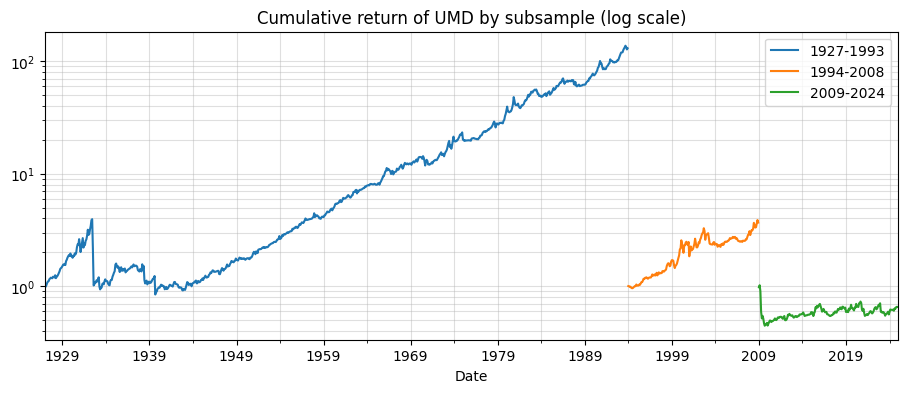

In [23]:
fig, ax = plt.subplots(figsize=(11, 4))
for k, (a, b) in list(SUBSAMPLES.items())[1:]:
    (1 + umd.loc[a:b]).cumprod().plot(ax=ax, label=k, logy=True)
ax.set_title("Cumulative return of UMD by subsample (log scale)")
ax.grid(True, which="both", alpha=0.4)
ax.legend()
plt.show()

#### (b) Has momentum changed over time?

**Yes, sharply in the most recent period.**

* **1927–1993 and 1994–2008:** momentum earned about 9–10% per year with Sharpe ratios of roughly 0.55–0.59. Publication in 1993 did not immediately kill the premium; 1994–2008 is actually the strongest subsample.
* **2009–2024:** the mean is slightly *negative* (≈ −1.3%/yr, Sharpe ≈ −0.08) at similar volatility (≈ 16%). The 2009 "momentum crash", which included a −34% month in April 2009, sits at the start of this period. Even excluding the crash, 2010–2024 averages only ≈ 3%/yr, about a third of the earlier premium.
* **Skewness is strongly negative** in every subsample (−3.9 pre-1993, −2.7 post-2009). Momentum carries crash risk: its worst months (July–Aug 1932: −46% and −53%; Apr 2009: −34%) come in sharp market rebounds after crashes, when past losers surge.
* **Correlations to MKT and HML stay negative** throughout, about −0.24 to −0.37 for MKT and −0.12 to −0.50 for HML.

In [24]:
# Supporting evidence for (c): alpha of UMD relative to MKT and HML, and tangency weights (1927-2024)
sub = ff[["MKT", "HML"]].join(umd).loc[:"2024"]
reg = sm.OLS(sub["UMD"], sm.add_constant(sub[["MKT", "HML"]])).fit()
print(f"UMD on MKT, HML (1927-2024): alpha = {reg.params['const']*12:.2%}/yr (t = {reg.tvalues['const']:.2f}), "
      f"beta_MKT = {reg.params['MKT']:.2f}, beta_HML = {reg.params['HML']:.2f}\n")


def tan_sharpe(mu, cov):
    w = np.linalg.solve(cov, mu)
    w = w / w.sum()
    return w, (w @ mu) / np.sqrt(w @ cov @ w) * np.sqrt(12)


mu, cov = sub.mean(), sub.cov()
rows = {}
for label, m in {"Actual UMD mean": mu, "UMD mean set to 0": mu.where(mu.index != "UMD", 0.0)}.items():
    w, sr = tan_sharpe(m.values, cov.values)
    _, sr_no = tan_sharpe(m[["MKT", "HML"]].values, cov.loc[["MKT", "HML"], ["MKT", "HML"]].values)
    rows[label] = {"w MKT": w[0], "w HML": w[1], "w UMD": w[2],
                   "Tangency SR (MKT,HML,UMD)": sr, "Tangency SR (MKT,HML only)": sr_no}
pd.DataFrame(rows).T

UMD on MKT, HML (1927-2024): alpha = 11.23%/yr (t = 7.73), beta_MKT = -0.24, beta_HML = -0.46



,w MKT,w HML,w UMD,"Tangency SR (MKT,HML,UMD)","Tangency SR (MKT,HML only)"
Actual UMD mean,0.2528,0.3358,0.4115,0.9372,0.5048
UMD mean set to 0,0.3486,0.3913,0.2600,0.5725,0.5048


#### (c) Is momentum an important piece of the ideal portfolio?

**Yes, the data support AQR's argument.**

* Over 1927–2024, UMD has a Sharpe ratio of about 0.45, comparable to the market.
* It is **negatively correlated with both the market (−0.35) and value (−0.41)**.
* Regressed on MKT and HML, it has an alpha of about **11%/yr (t ≈ 7.7)**: momentum is not spanned by the market and value.
* Adding UMD to MKT and HML raises the tangency Sharpe ratio from about **0.51 to 0.94**.

**What if transaction costs push momentum's mean to roughly zero?** There is still evidence it is valuable. A zero-mean asset that is *negatively correlated* with the other holdings works as a hedge and lowers portfolio variance.

* With UMD's mean set to 0, the tangency portfolio still puts about **26%** in UMD.
* The Sharpe ratio still rises, from 0.51 to 0.57, because of the diversification against value and the market.

**Caveats:** the strong negative skew (crash risk) and the weak 2009–2024 period mean the gain is smaller in recent data and comes with tail risk.

### 2.2 Long-only momentum
$\tilde r^{\text{momU:FF}} = \tfrac12(r^{\text{momBU}} + r^{\text{momSU}}) - r^f$
#### (a) Table 2 (1994–2024)

In [25]:
S, E = "1994", "2024"
mom_long_only = 0.5 * (size_sorts["BIG HiPRIOR"] + size_sorts["SMALL HiPRIOR"]) - rf

table2 = pd.DataFrame({
    "Long-and-short (mom:FF)": mom_stats(umd.loc[S:E]),
    "Long-only (momU:FF)": mom_stats(mom_long_only.loc[S:E]),
    "Market (for reference)": mom_stats(ff["MKT"].loc[S:E]),
}).T
table2

,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
Long-and-short (mom:FF),0.0431,0.1672,0.2575,-1.4610,-0.3105,-0.2104
Long-only (momU:FF),0.1161,0.1780,0.6524,-0.4420,0.9040,-0.1163
Market (for reference),0.0898,0.1554,0.5778,-0.6046,1.0000,-0.0890


In [26]:
# Alpha of long-only momentum relative to the market (1994-2024)
r = sm.OLS(mom_long_only.loc[S:E], sm.add_constant(ff.loc[S:E, ["MKT"]])).fit()
print(f"Long-only momentum on MKT: alpha = {r.params['const']*12:.2%}/yr (t = {r.tvalues['const']:.2f}), "
      f"beta = {r.params['MKT']:.2f}, R2 = {r.rsquared:.2f}")

Long-only momentum on MKT: alpha = 2.31%/yr (t = 1.67), beta = 1.04, R2 = 0.82


#### (b) Is long-only as attractive on mean, vol and Sharpe?

On a standalone basis, long-only looks *better*:

* **Mean:** ≈ 11.6% vs 4.3% for long-short.
* **Vol:** similar, ≈ 17.8% vs 16.7%.
* **Sharpe:** ≈ 0.65 vs 0.26.
* **Skewness:** less negative.

The comparison is misleading, though. Long-only momentum is mostly **market exposure**: it holds winners but does not short losers, so it collects the equity premium. Its Sharpe ratio is only modestly above the market's over the same period (≈ 0.58), and its alpha relative to the market is small (see (c)).

#### (c) Is long-only as diversifying?

**No.** Long-only momentum has a **correlation of about 0.90 with the market**, versus −0.31 for long-short. Its correlation with HML is still negative (≈ −0.12) but smaller in magnitude than long-short's (≈ −0.21).

The main benefit of momentum in a portfolio is diversification against the market and value. Long-only momentum gives most of that up: in practice it is "the market plus a momentum tilt". Regressed on MKT, it has β ≈ 1.04, R² ≈ 0.82 and an alpha of only ≈ 2.3%/yr (t ≈ 1.7).

#### (d) Cumulative returns, 1994–2024

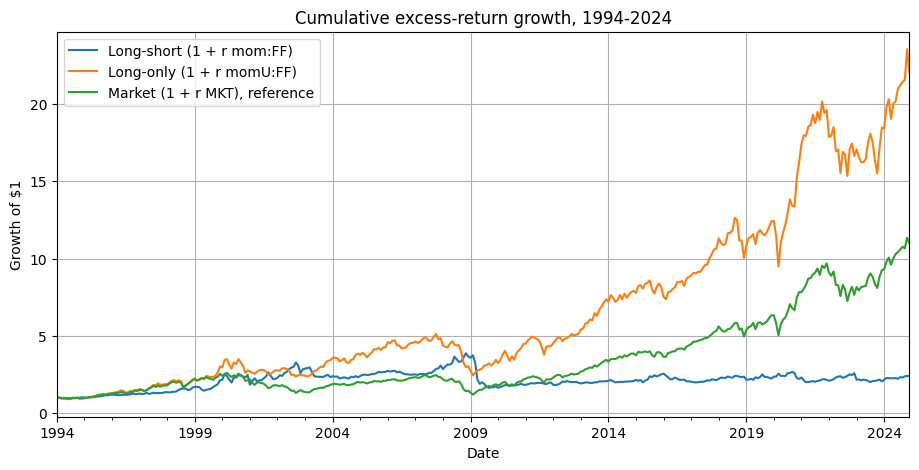

In [27]:
cum = pd.DataFrame({
    "Long-short (1 + r mom:FF)": (1 + umd.loc[S:E]).cumprod(),
    "Long-only (1 + r momU:FF)": (1 + mom_long_only.loc[S:E]).cumprod(),
    "Market (1 + r MKT), reference": (1 + ff["MKT"].loc[S:E]).cumprod(),
})
ax = cum.plot(figsize=(11, 5), title="Cumulative excess-return growth, 1994-2024", grid=True)
ax.set_ylabel("Growth of $1")
plt.show()

### 2.3 Is momentum just data mining? Decile constructions

In [28]:
momD1 = deciles["Hi PRIOR"] - deciles["Lo PRIOR"]
momD3 = deciles.iloc[:, 7:10].mean(axis=1) - deciles.iloc[:, 0:3].mean(axis=1)
momD5 = deciles.iloc[:, 5:10].mean(axis=1) - deciles.iloc[:, 0:5].mean(axis=1)

table3 = pd.DataFrame({
    "momD1 (10 minus 1)": mom_stats(momD1.loc[S:E]),
    "momD3 (8-10 minus 1-3)": mom_stats(momD3.loc[S:E]),
    "momD5 (6-10 minus 1-5)": mom_stats(momD5.loc[S:E]),
}).T
table3

,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
momD1 (10 minus 1),0.0810,0.2996,0.2703,-1.3012,-0.3242,-0.2375
momD3 (8-10 minus 1-3),0.0297,0.1937,0.1535,-1.3411,-0.3632,-0.2121
momD5 (6-10 minus 1-5),0.0173,0.1343,0.1285,-1.4215,-0.3544,-0.2087


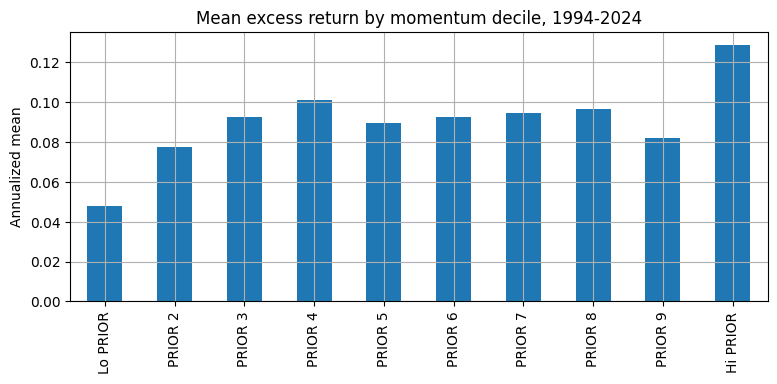

In [29]:
# Mean annualized excess return by decile (1994-2024)
dec_mean = deciles.loc[S:E].sub(rf.loc[S:E], axis=0).mean() * 12
ax = dec_mean.plot.bar(figsize=(9, 3.5), title="Mean excess return by momentum decile, 1994-2024", grid=True)
ax.set_ylabel("Annualized mean")
plt.show()

#### (a) See Table 3 above.

#### (b) Do the tradeoffs match the theory?

**Yes.** A more extreme sort (fewer deciles in each leg) buys a stronger signal at the cost of less diversification:

* **momD1:** the highest mean (≈ 8.1%) but also by far the highest vol (≈ 30%). The 1-decile legs hold fewer, more extreme stocks, so idiosyncratic risk is less diversified away. This construction would also carry the highest turnover and trading costs.
* **momD5:** the lowest vol (≈ 13%) but also the lowest mean (≈ 1.7%). Including middle deciles dilutes the signal.
* **Sharpe ratio:** it declines as the sort widens (0.27 → 0.15 → 0.13). Signal strength falls faster than volatility.
* **Robustness:** skewness and correlations to MKT and HML are very similar across all three. The sign and the diversification properties of momentum do not depend on where the threshold is drawn, which argues against data mining.

#### (c) Should AQR use a 1-decile or 5-decile construction?

**Neither extreme.** For a retail product that must be cheap to trade and to hold:

* **1-decile** has the best gross Sharpe, but ~30% vol, concentrated positions and very high turnover. Trading costs would eat into its edge, and the volatility is hard for retail investors to stomach.
* **5-decile** is well diversified and low-turnover, but it is close to holding the whole market. Its premium is small (≈ 1.7%) and could be erased by fees.

An intermediate cut is the sensible compromise. AQR's actual design uses roughly the top third of stocks, close to the 3-decile construction.

#### (d) momD3 vs. the FF construction (Table 2, top row)

They are broadly similar: both are 3-decile long-short portfolios, with similar skewness (≈ −1.3 to −1.5) and similar correlations to MKT (≈ −0.31 to −0.36) and HML (≈ −0.21). But **momD3 has a lower mean (≈ 3.0% vs 4.3%) and higher vol (≈ 19% vs 17%)**, so its Sharpe ratio is lower (0.15 vs 0.26).

The FF construction sorts within small and big stocks separately and weights them 50/50, so the long and short legs are **size-neutral**. That removes an unpriced size bet and lowers volatility. FF also tilts toward small stocks, which have the stronger momentum effect (see 2.4).

### 2.4 Momentum in small vs. big stocks

In [30]:
momS = size_sorts["SMALL HiPRIOR"] - size_sorts["SMALL LoPRIOR"]
momB = size_sorts["BIG HiPRIOR"] - size_sorts["BIG LoPRIOR"]

table4 = pd.DataFrame({
    "All stocks (mom:FF)": mom_stats(umd.loc[S:E], corr_cols=("MKT",)),
    "Small stocks (momS)": mom_stats(momS.loc[S:E], corr_cols=("MKT",)),
    "Large stocks (momB)": mom_stats(momB.loc[S:E], corr_cols=("MKT",)),
}).T
table4

,mean,vol,Sharpe,skewness,corr. to MKT
All stocks (mom:FF),0.0431,0.1672,0.2575,-1.4610,-0.3105
Small stocks (momS),0.0614,0.1691,0.3631,-1.8042,-0.3102
Large stocks (momB),0.0246,0.1823,0.1351,-0.8745,-0.2819


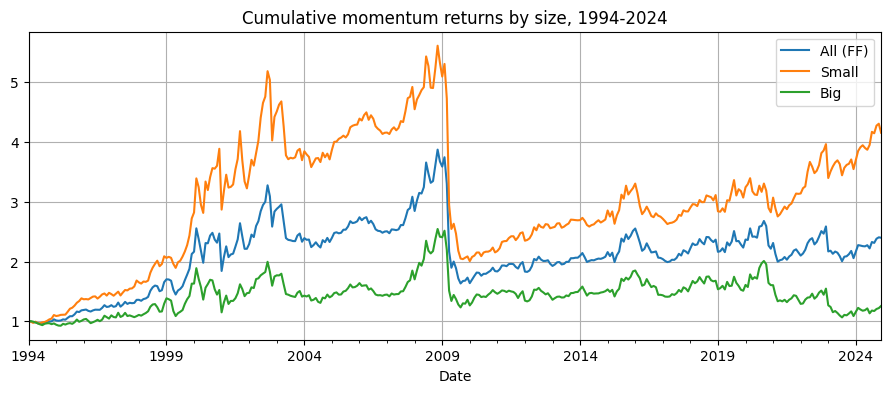

In [31]:
pd.DataFrame({k: (1 + v.loc[S:E]).cumprod() for k, v in
              {"All (FF)": umd, "Small": momS, "Big": momB}.items()}).plot(
    figsize=(11, 4), title="Cumulative momentum returns by size, 1994-2024", grid=True)
plt.show()

#### (b) Is momentum mostly driven by small stocks?

**Partly, yes.**

* **Small-stock momentum** earns about **6.1%/yr (Sharpe ≈ 0.36)**.
* **Big-stock momentum** earns only about **2.5%/yr (Sharpe ≈ 0.14)**, with slightly *higher* volatility (≈ 18% vs 17%).

So over 1994–2024 a large share of momentum's profit comes from small stocks, which are also the most expensive to trade.

Large-stock momentum still delivers a **positive** excess return at **comparable risk**, with less negative skew (−0.87 vs −1.80). It also keeps a similar negative correlation with the market (≈ −0.28), so the diversification benefit survives. A big-stock product is viable, but investors should expect a smaller premium than the headline FF factor.

### 2.5 Assessment of the AQR retail product

**It captures the important features of FF momentum:**

* It ranks on 12-1 month past returns, skipping the most recent month to avoid short-term reversal.
* It holds roughly the top third of stocks, like the 3-decile construction.
* Its exposure to the momentum premium is diversified across many names.

**Key differences:**

1. **Long-only.** The product cannot short losers, so it is ~0.9 correlated with the market and gives up momentum's main diversification benefit (§2.2). It is better described as "market + momentum tilt" and should be judged by its alpha against the market.
2. **Large and mid caps.** The product focuses on liquid stocks for capacity and trading-cost reasons. Big-stock momentum has a much smaller premium than small-stock momentum (§2.4), so expected returns will fall short of the FF factor.
3. **Recent performance.** Momentum's premium in 2009–2024 is roughly zero, and its negative skew (crash risk) is severe.

**Suggested modifications:**

* **Control turnover and costs:** use a wider band (≈ 3 deciles, not 1), apply buffer and hysteresis rules before trading, and rebalance quarterly rather than monthly.
* **Sort within size or industry buckets** (as FF do), so the product is not an unintended size or sector bet.
* **Combine momentum with value** (e.g. in a value-momentum blend). Their correlation is negative (−0.4), so the combined portfolio is more stable than either style alone.
* **Manage crash risk:** volatility-scale the momentum exposure, cutting it when recent momentum volatility is high (e.g. after market crashes).
* **Offer a 130/30 or long-short version** for investors who can use it, to recover the diversification benefit.